# Building Neural Networks with TensorFlow/Keras

---

## Theory

**TensorFlow** is an open-source machine learning library developed by Google that allows building and training deep learning models efficiently.  

**Keras** is a high-level API integrated with TensorFlow that simplifies the process of building neural networks by providing easy-to-use abstractions for layers, models, and training routines.

---

### Key Concepts

1. **Sequential API:**  
   Used for creating models layer-by-layer in a linear stack. Ideal for simple feedforward networks.

2. **Functional API:**  
   Allows building complex models with multiple inputs, outputs, or shared layers.

3. **Layers:**  
   Neural networks are built by stacking layers such as:
   - `Dense` (fully connected layer)
   - `Conv2D` (convolutional layer for images)
   - `LSTM` (for sequential data)
   - Activation functions can be applied via `activation` parameter or separate layers.

4. **Compiling the Model:**  
   Before training, a model is compiled with:
   - **Optimizer:** Method to update weights (`SGD`, `Adam`, etc.)
   - **Loss Function:** Guides the training (`mse`, `binary_crossentropy`, `categorical_crossentropy`, etc.)
   - **Metrics:** To monitor performance (`accuracy`, `mae`, etc.)

5. **Training the Model:**  
   Done using `model.fit()` with:
   - Training data (`X_train`, `y_train`)
   - Number of epochs (iterations over the dataset)
   - Batch size (number of samples per weight update)
   - Validation data (optional) to monitor performance on unseen data.

6. **Evaluating and Predicting:**  
   - `model.evaluate()` to check loss and metrics on test data.
   - `model.predict()` to make predictions on new data.

---

### Workflow Summary

1. Prepare dataset and preprocess.  
2. Build the model using Sequential or Functional API.  
3. Compile the model with optimizer, loss, and metrics.  
4. Train the model with `fit()`.  
5. Evaluate on test data.  
6. Make predictions with `predict()`.  
7. (Optional) Visualize training history (loss/accuracy curves).  


Epoch 1/50


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.2812 - loss: 1.1027 - val_accuracy: 0.5833 - val_loss: 0.9624
Epoch 2/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4062 - loss: 1.0487 - val_accuracy: 0.5000 - val_loss: 0.9656
Epoch 3/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.3750 - loss: 1.0236 - val_accuracy: 0.3750 - val_loss: 0.9787
Epoch 4/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4062 - loss: 1.0032 - val_accuracy: 0.5417 - val_loss: 0.9696
Epoch 5/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6875 - loss: 0.9883 - val_accuracy: 0.7083 - val_loss: 0.9602
Epoch 6/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7708 - loss: 0.9702 - val_accuracy: 0.6250 - val_loss: 0.9580
Epoch 7/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7812 - loss: 0.9554 - val_accuracy: 0.6250 - val_loss: 0.9443
Epoch 8/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7812 - loss: 0.9415 - val_accuracy: 0.7500 - val_loss: 0.9216
Ep

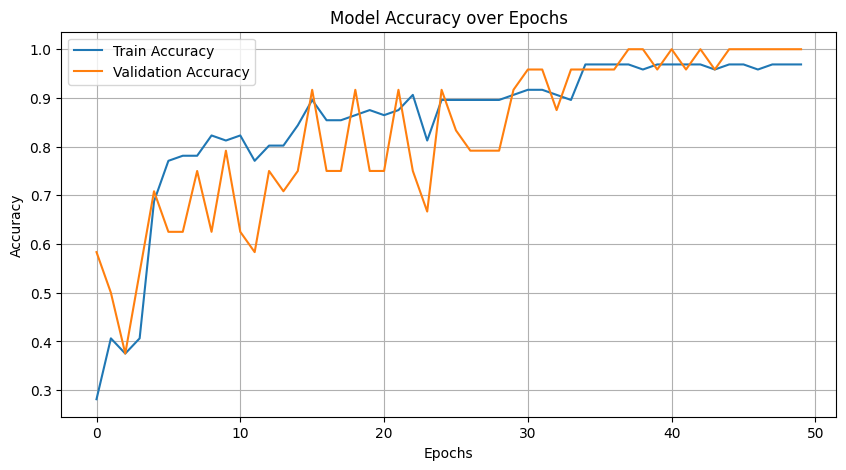

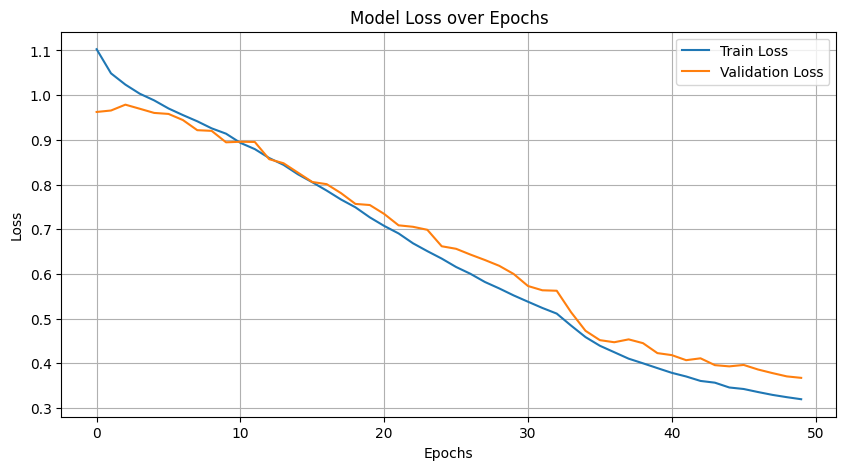

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
import matplotlib.pyplot as plt

# 1. Load dataset (Iris dataset)
iris = load_iris()
X = iris.data
y = iris.target.reshape(-1, 1)

# 2. One-hot encode target
encoder = OneHotEncoder(sparse_output=False)  # updated for latest sklearn
y_encoded = encoder.fit_transform(y)

# 3. Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42
)

# 4. Build Neural Network (Sequential API)
model = Sequential([
    Dense(10, input_shape=(X.shape[1],), activation='relu'),  # Hidden layer
    Dense(8, activation='relu'),                               # Hidden layer
    Dense(y_encoded.shape[1], activation='softmax')           # Output layer
])

# 5. Compile the model
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# 6. Train the model
history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=8,
    verbose=1
)

# 7. Evaluate the model on test data
loss, accuracy = model.evaluate(X_test, y_test)
print(f"\nTest Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")

# 8. Plot training history
plt.figure(figsize=(10,5))
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Model Accuracy over Epochs')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10,5))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Model Loss over Epochs')
plt.legend()
plt.grid(True)
plt.show()
